# Step 1: Understand the data

Target y = Diabetes_binary. X = the other 21 columns.

0 = no diabetes. 1 = prediabetes or diabetes.

Imbalanced: 86.1% class 0, 13.9% class 1. So accuracy alone is misleading.

Feature types: BMI numeric, HighBP binary, Age ordinal.

Numbers in the CSV are not all measurements. Ordered codes are not plain numbers.


In [28]:
import pandas as pd

df = pd.read_csv("diabetes_binary_classification_data.csv")

print(df.shape)
print(df["Diabetes_binary"].value_counts())
print(df["Diabetes_binary"].value_counts(normalize=True).round(3))
print(df.isna().sum().sum())
print(df.duplicated().sum())


(253680, 22)
Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64
Diabetes_binary
0.0    0.861
1.0    0.139
Name: proportion, dtype: float64
0
24206


# Step 2: EDA

Look at all features against Diabetes_binary. Group by type, since the right
plot depends on the type.

- Numeric: mean/median per class, box plots.
- Binary: share of class 1 per category.
- Ordinal: share of class 1 across the ordered codes.

Use shares, not correlation, for binary and ordinal codes. EDA shows
associations, not causes.

                   BMI        MentHlth        PhysHlth       
                  mean median     mean median     mean median
Diabetes_binary                                              
0.0              27.81   27.0     2.98    0.0     3.64    0.0
1.0              31.94   31.0     4.46    0.0     7.95    1.0


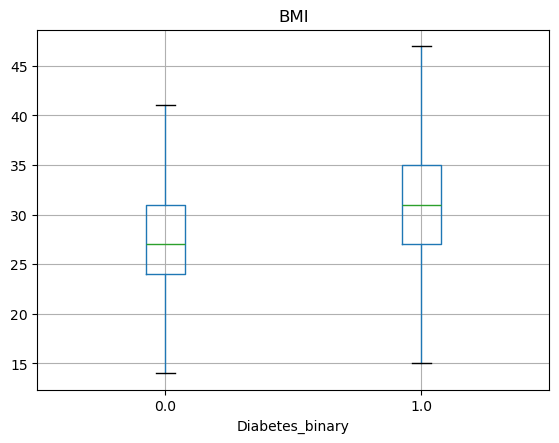

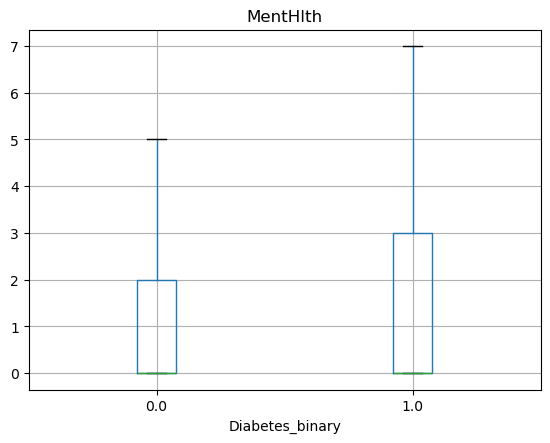

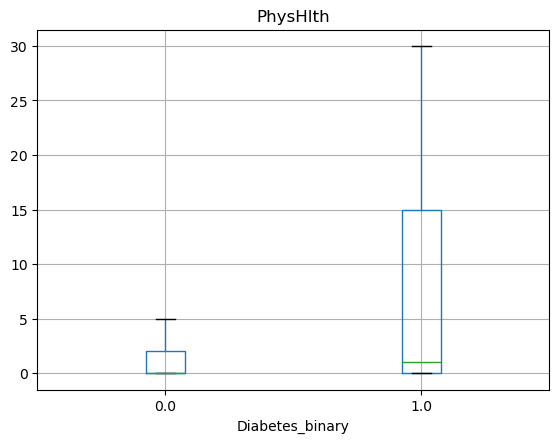


HighBP
Diabetes_binary    0.0    1.0
HighBP                       
0.0              0.940  0.060
1.0              0.756  0.244

HighChol
Diabetes_binary   0.0   1.0
HighChol                   
0.0              0.92  0.08
1.0              0.78  0.22

CholCheck
Diabetes_binary    0.0    1.0
CholCheck                    
0.0              0.975  0.025
1.0              0.856  0.144

Smoker
Diabetes_binary    0.0    1.0
Smoker                       
0.0              0.879  0.121
1.0              0.837  0.163

Stroke
Diabetes_binary    0.0    1.0
Stroke                       
0.0              0.868  0.132
1.0              0.682  0.318

HeartDiseaseorAttack
Diabetes_binary        0.0   1.0
HeartDiseaseorAttack            
0.0                   0.88  0.12
1.0                   0.67  0.33

PhysActivity
Diabetes_binary    0.0    1.0
PhysActivity                 
0.0              0.789  0.211
1.0              0.884  0.116

Fruits
Diabetes_binary    0.0    1.0
Fruits                       
0.0    

In [29]:
import matplotlib.pyplot as plt

num = ["BMI", "MentHlth", "PhysHlth"]
bin_ = ["HighBP", "HighChol", "CholCheck", "Smoker", "Stroke",
        "HeartDiseaseorAttack", "PhysActivity", "Fruits", "Veggies",
        "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex"]
ord_ = ["GenHlth", "Age", "Education", "Income"]

# --- Numeric ---
print(df.groupby("Diabetes_binary")[num].agg(["mean", "median"]).round(2))

for c in num:
    df.boxplot(column=c, by="Diabetes_binary", showfliers=False)
    plt.title(c)
    plt.suptitle("")
    plt.show()

# --- Binary ---
for c in bin_:
    print(f"\n{c}")
    print(pd.crosstab(df[c], df["Diabetes_binary"], normalize="index").round(3))

# --- Ordinal ---
for c in ord_:
    print(f"\n{c}")
    print(pd.crosstab(df[c], df["Diabetes_binary"], normalize="index").round(3))


## Findings:

Numeric: BMI differs most (mean 27.8 vs 31.9). PhysHlth shifts too. MentHlth
is weak (median 0 in both classes).

Binary: biggest gaps in HeartDiseaseorAttack, Stroke, DiffWalk, HighBP.
PhysActivity and HvyAlcoholConsump go the other way. Sex, Smoker,
AnyHealthcare and NoDocbcCost are almost flat.

Ordinal: GenHlth rises 0.03 to 0.38 (strongest trend). Age rises to about 0.22
then levels off. Education falls 0.27 to 0.10. Income falls 0.24 to 0.08.

All of this is association, not causation.

# Step 3: Split

Stratify on y so TRAIN and TEST keep the same 86/14 mix. TEST stays untouched
until evaluation.


In [30]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Diabetes_binary"])
y = df["Diabetes_binary"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print("Class 1 share - train:", round(y_train.mean(), 3),
      "| test:", round(y_test.mean(), 3))


(202944, 21) (50736, 21)
Class 1 share - train: 0.139 | test: 0.139


# Step 4: Prepare

Three types, three treatments:

- Numeric: StandardScaler (different ranges, scale sensitive model).
- Binary: passthrough (already 0/1).
- Ordinal: OrdinalEncoder with fixed order (ranked groups, not equal gaps).

Scaling is learned from TRAIN only, via the Pipeline.


In [31]:
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer

num_cols = ["BMI", "MentHlth", "PhysHlth"]
bin_cols = ["HighBP", "HighChol", "CholCheck", "Smoker", "Stroke",
            "HeartDiseaseorAttack", "PhysActivity", "Fruits", "Veggies",
            "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex"]
ord_cols = ["GenHlth", "Age", "Education", "Income"]

ordinal_orders = [list(range(1, 6)), list(range(1, 14)),
                  list(range(1, 7)), list(range(1, 9))]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("bin", "passthrough", bin_cols),
    ("ord", OrdinalEncoder(categories=ordinal_orders), ord_cols),
])

print("Numeric:", len(num_cols), "| Binary:", len(bin_cols), "| Ordinal:", len(ord_cols))


Numeric: 3 | Binary: 14 | Ordinal: 4


# Step 5: Fit

Fit the whole Pipeline on TRAIN only. The Pipeline runs the scaler and encoder
inside the fit, so nothing from TEST leaks in.


In [32]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=2000)),
])

model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('bin', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contain

# Step 6: Evaluate on TEST

Confusion matrix, accuracy, precision, recall, F1.


In [33]:
from sklearn.metrics import (confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score)

y_pred = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]

print(confusion_matrix(y_test, y_pred))
print("accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("precision:", round(precision_score(y_test, y_pred), 3))
print("recall   :", round(recall_score(y_test, y_pred), 3))
print("f1       :", round(f1_score(y_test, y_pred), 3))


[[42618  1049]
 [ 5950  1119]]
accuracy : 0.862
precision: 0.516
recall   : 0.158
f1       : 0.242


# Step 7: Threshold 0.50 vs 0.40

Same probabilities, different cutoff. Lower threshold finds more cases but
raises false positives.


In [34]:
for t in [0.50, 0.40]:
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"\nThreshold {t}")
    print("accuracy :", round(accuracy_score(y_test, pred), 3))
    print("precision:", round(precision_score(y_test, pred), 3))
    print("recall   :", round(recall_score(y_test, pred), 3))
    print("f1       :", round(f1_score(y_test, pred), 3))
    print("false positives:", fp, "| false negatives:", fn)



Threshold 0.5
accuracy : 0.862
precision: 0.516
recall   : 0.158
f1       : 0.242
false positives: 1049 | false negatives: 5950

Threshold 0.4
accuracy : 0.856
precision: 0.472
recall   : 0.269
f1       : 0.343
false positives: 2129 | false negatives: 5167


# Step 8: Conclusion

Key findings:

- Imbalanced classes (86/14), so accuracy alone is misleading.
- EDA: BMI separates the classes most (27.8 vs 31.9). GenHlth has the
  strongest ordinal trend (0.03 to 0.38). Age, Income and Education show
  clear gradients. Heart disease, stroke, DiffWalk and HighBP have the
  largest binary gaps.
- Model: accuracy 0.862, but recall only 0.158. It misses 5950 of 7069
  in class 1.
- Threshold 0.40: recall up to 0.269, F1 up to 0.343, precision down to
  0.472, false positives up from 1049 to 2129.

Limitations:

1. Self-reported survey data, so misreporting is possible.
2. Cross-sectional, so no direction of effect can be read off it.
3. Target merges prediabetes and diabetes.
4. Imbalanced classes, so the model favours class 0.

Association is not causation.
